In [1]:
import os, sys, glob, io, contextlib, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
import scipy.sparse as sp
from scipy.sparse.csgraph import shortest_path, connected_components
from scipy.stats import spearmanr
from sklearn.neighbors import NearestNeighbors
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # e.g. Bischoff2021_Lung-2
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Lung
data_name = re.sub(r'-\d+$', '', name)                  # strip attempt suffix -> Bischoff2021_Lung
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + data_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| input:', 'Data_'+data_name)

dataset: Bischoff2021_Lung-2 | category: Lung | input: Data_Bischoff2021_Lung


In [3]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.dropna().drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{l}: {g.size}/{feat[src].size} genes present')

Gast: 80/81 genes present
pSom: 95/98 genes present
Crest: 103/104 genes present


In [4]:
# GATE 2 evidence — module geography and relationships (judged on the signature UMAPs).
g=adata.obs['Gast'].values; p=adata.obs['pSom'].values; c=adata.obs['Crest'].values
gz=(g-g.mean())/g.std(); pz=(p-p.mean())/p.std(); cz=(c-c.mean())/c.std()
print('raw score correlations:')
print(f'  Gast-pSom  {np.corrcoef(g,p)[0,1]:+.3f}   Gast-Crest {np.corrcoef(g,c)[0,1]:+.3f}   pSom-Crest {np.corrcoef(p,c)[0,1]:+.3f}')
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    print(f'  {a} vs {b}: {np.corrcoef(adata.obs[a],adata.obs[b])[0,1]:+.2f}')
# HUB = Gast&pSom co-high zone; is it Crest-low (the defining non-branching signature)?
hub = np.minimum(gz,pz); adata.obs['hub_score']=hub; hm = hub>np.percentile(hub,80)
print(f'HUB (top-20%% Gast&pSom co-high): n={int(hm.sum())}, Crest z={cz[hm].mean():+.2f} vs non-hub {cz[~hm].mean():+.2f}')
print(f'frac cells score>0: Gast {(g>0).mean():.2f}  pSom {(p>0).mean():.2f}  Crest {(c>0).mean():.2f}')

raw score correlations:
  Gast-pSom  -0.146   Gast-Crest -0.417   pSom-Crest -0.497
smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: -0.18
  Crest_sm vs Gast_sm: -0.41
  Crest_sm vs pSom_sm: -0.65
HUB (top-20%% Gast&pSom co-high): n=2677, Crest z=-0.82 vs non-hub +0.20
frac cells score>0: Gast 0.14  pSom 0.94  Crest 0.16


In [5]:
# GATE 2 DECISION (judged visually on the signature maps below)
# NON-BRANCHING case (spec S1): programs present but not resolved into two competing arms.
#  - Crest is a clean INVERSE/terminal gradient: anti-correlates Gast (-0.42) and pSom (-0.50);
#    the Gast&pSom co-high hub is strongly Crest-low -> defining non-branching signature. GO.
#  - FLAG (attenuated): pSom is near-ubiquitous (score>0 in ~96%% of cells) and Gast is sparse
#    (~14%%); Gast/pSom co-variation is weak/slightly negative rather than a strong shared
#    gradient, and the gradient along pseudotime is shallow. Pattern present but weaker than Kurten.
#  - No bifurcation -> GATE 3 = NA (branching-only).
print('GATE 2: Crest inverse/terminal gradient opposing a Gast/pSom hub -> GO (non-branching), FLAGGED attenuated')
print('GATE 3: no bifurcation -> NA')

GATE 2: Crest inverse/terminal gradient opposing a Gast/pSom hub -> GO (non-branching), FLAGGED attenuated
GATE 3: no bifurcation -> NA


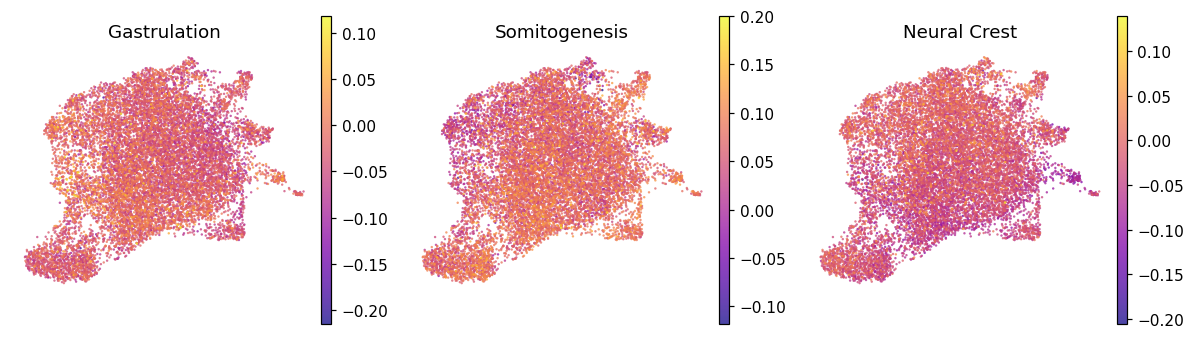

In [6]:
# signature maps in 2-D (equal aspect), plasma; + individual PDFs and colorbars
plot = adata.copy()
fig, axes = plt.subplots(1,3, figsize=(11,3.2))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.75, size=10, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_aspect('equal')
fig.tight_layout(); plt.show()

<string>:12: UserWarning: Adding colorbar to a different Figure <Figure size 360x300 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Gast_signature.pdf + colorbar
<string>:12: UserWarning: Adding colorbar to a different Figure <Figure size 360x300 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved pSom_signature.pdf + colorbar
<string>:12: UserWarning: Adding colorbar to a different Figure <Figure size 360x300 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
saved Crest_signature.pdf + colorbar


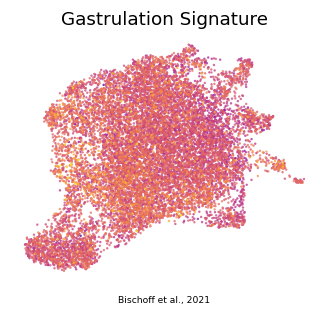

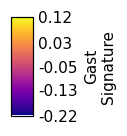

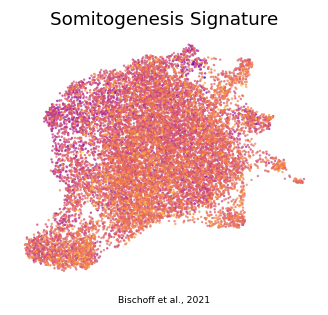

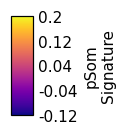

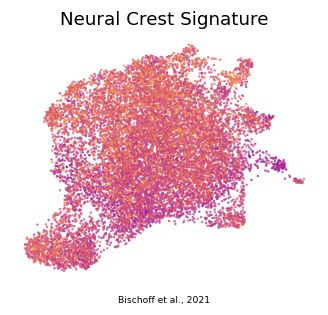

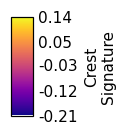

In [7]:
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.6,3.0))
    sc.pl.umap(adata, color=m, cmap='plasma', alpha=.75, size=10, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_aspect('equal')
    ax.text(.5,-.08,'Bischoff et al., 2021', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')
plt.show()

In [8]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (13382, 24764)
